# Residual produksi

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Vintage B, 34 provinsi, 2017–2024.
--> Indeks = efek tahun, 2017 = 100.
--> Gambar: `01 Data/IO-IRIO-NA/output/`.


## Definisi

Residual --> vintage B, `01 Data/TFP/output/modal_riil`. Modal = arus PMTB riil (`4_ADHK`). b1 ≈ 0,40, b2 ≈ 0,15, jumlah ≈ 0,55. Indeks = efek tahun, 2017 = 100, sampai 2024. Tahun 2025 di luar jendela.

Ekuitas --> distribusi: −ln(P1+1), IPM, Gini, upah rata-rata, indeks demokrasi. Partisipasi sekolah di berkas bertanda minus; gambar membalik tandanya. IPM ikut memuat sekolah.

Harga --> PMA dan PMDN nominal. Riil = jumlah `4_ADHB` / jumlah `4_ADHK`, basis 2010.

Korelat --> FE2W dan OLS gabungan, `Determinan TFP Provinsi.log`. Y = residual `konstruksi/TFP Provinsi 2017-2024.dta`. N = 272, 34 provinsi, 2017–2024. Mengikuti vintage B; beda tingkat konstan karena satuan. OLS gabungan = antarprovinsi. FE2W = di dalam provinsi, setelah efek tahun.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "02 Code" / "IO-IRIO-NA"))
import types, sys
chapter71 = types.ModuleType('chapter71')
exec(r'''"""Data for the chapter 7.1 notebooks.

The notebooks draw the figures. This module only loads and shapes series
that already exist in the project.

Working definitions, used until the chapter text says otherwise:

- Equity is distributional. In the stored determinant regression it is
  poverty depth entered as −ln(P1+1), the human-development index, the Gini
  coefficient, the average wage, and the democracy index. It is not firm
  equity finance and it is not ownership (PMA versus PMDN).
- Real PMA and PMDN use the implicit national GFCF deflator,
  sum of provincial ``4_ADHB`` over sum of provincial ``4_ADHK``.
  Both series are nominal in the workbook. They have no price index of their own.
- The national TFP index and the growth-accounting bars are vintage B
  (``01 Data/TFP/output/modal_riil``), 2017–2024. The residual is a
  PMTB-flow production residual, not Hicks-neutral technology.
- Partial associations come from the stored FE2W and pooled OLS fits in
  ``Determinan TFP Provinsi.log``. The dependent variable is the residual in
  ``01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2024.dta``. That file
  tracks vintage B (level correlation about 0.998) with a constant level gap
  from units. It is not the vintage C paste.
"""

from __future__ import annotations

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

PROV34 = {
    11: "Aceh", 12: "Sumatera Utara", 13: "Sumatera Barat", 14: "Riau",
    15: "Jambi", 16: "Sumatera Selatan", 17: "Bengkulu", 18: "Lampung",
    19: "Kep. Bangka Belitung", 21: "Kep. Riau",
    31: "DKI Jakarta", 32: "Jawa Barat", 33: "Jawa Tengah", 34: "DI Yogyakarta",
    35: "Jawa Timur", 36: "Banten",
    51: "Bali", 52: "Nusa Tenggara Barat", 53: "Nusa Tenggara Timur",
    61: "Kalimantan Barat", 62: "Kalimantan Tengah", 63: "Kalimantan Selatan",
    64: "Kalimantan Timur", 65: "Kalimantan Utara",
    71: "Sulawesi Utara", 72: "Sulawesi Tengah", 73: "Sulawesi Selatan",
    74: "Sulawesi Tenggara", 75: "Gorontalo", 76: "Sulawesi Barat",
    81: "Maluku", 82: "Maluku Utara", 91: "Papua Barat", 94: "Papua",
}

# Letter codes match the IO 17-sector table. ``flip`` is −1 when the stored
# regressor is the negative of the labeled concept, so a plotted positive
# coefficient means more of the labeled concept.
CORRELATE_GROUPS = [
    ("Pendidikan", [
        ("z_ln_lama_sekolah_mean", "Rata-rata lama sekolah", 1),
        ("z_ln_lama_sekolah_harapan", "Harapan lama sekolah", 1),
        ("z_db_sd", "Partisipasi SD", -1),
        ("z_db_smp", "Partisipasi SMP", -1),
        ("z_db_sma", "Partisipasi SMA", -1),
        ("z_db_kampus", "Partisipasi perguruan tinggi", -1),
    ]),
    ("Ekuitas dan distribusi", [
        ("z_ln_p1", "Kedalaman kemiskinan yang lebih rendah", 1),
        ("z_ln_ipm", "Indeks pembangunan manusia", 1),
        ("z_gini", "Gini, lebih tinggi berarti lebih timpang", 1),
        ("z_ln_upah_rata", "Upah rata-rata", 1),
        ("z_ln_indeks_demokrasi", "Indeks demokrasi", 1),
    ]),
    ("Infrastruktur", [
        ("z_ln_jalan_mantap", "Jalan kondisi baik", 1),
        ("z_ln_kargo_udara", "Kargo udara", 1),
        ("z_ln_kargo_kapal", "Kargo laut", 1),
        ("z_ln_kargo_kereta", "Kargo kereta", 1),
        ("z_ln_penumpang_total", "Penumpang", 1),
        ("z_ln_airport_logistik", "Bandara logistik", 1),
        ("z_ln_airport_komersil", "Bandara komersial", 1),
    ]),
    ("Iklim usaha", [
        ("z_price", "Tingkat harga", 1),
        ("z_ln_rasio_pad", "Rasio PAD", 1),
        ("z_ln_pertumbuhan_pdrb_adhb", "Pertumbuhan PDRB nominal", 1),
        ("z_ln_apbd_belanja", "Belanja pemerintah daerah", 1),
        ("z_ln_indeks_lingkungan", "Kualitas lingkungan", 1),
        ("z_ln_indeks_hijau", "Kualitas tutupan lahan", 1),
        ("z_ln_indeks_biru", "Kualitas air", 1),
        ("z_ln_crime_risk", "Risiko kejahatan", 1),
        ("z_ln_crime_rate", "Tingkat kejahatan", 1),
    ]),
]

SECTORS = [
    ("A", "Pertanian"), ("B", "Pertambangan"), ("C", "Industri pengolahan"),
    ("D", "Listrik dan gas"), ("E", "Air dan limbah"), ("F", "Konstruksi"),
    ("G", "Perdagangan"), ("H", "Transportasi dan pergudangan"), ("I", "Akomodasi dan makan minum"),
    ("J", "Informasi dan komunikasi"), ("K", "Jasa keuangan"), ("L", "Real estat"),
    ("MN", "Jasa perusahaan"), ("O", "Administrasi pemerintahan"), ("P", "Pendidikan"),
    ("Q", "Kesehatan"), ("RSTU", "Jasa lainnya"),
]
SECTOR_ID = {code: i + 1 for i, (code, _) in enumerate(SECTORS)}

# PMA and PMDN are million rupiah. GFCF (4_ADHB) and GRDP are billion rupiah.
PMA_TO_TRILLION = 1e6
FLOW_TO_TRILLION = 1e3
Z80 = 1.2815515655446004
HOLDOUT_YEARS = (2024, 2025)
FORECAST_YEARS = (2026, 2027, 2028, 2029)
ARIMA_ORDERS = ((0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 0, 0), (0, 0, 1))


def find_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")


def parse_num(series: pd.Series) -> pd.Series:
    """Indonesian decimal commas and scientific notation such as ``1,13E+08``."""
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series, errors="coerce")
    text = series.astype(str).str.strip()
    text = text.replace({"": pd.NA, ".": pd.NA, "nan": pd.NA, "None": pd.NA, "-": pd.NA})
    text = text.str.replace(",", ".", regex=False)
    return pd.to_numeric(text, errors="coerce")


def _workbook(root: Path) -> Path:
    return root / "01 Data" / "BKPM" / "processed" / "Dataset Provinsi.xlsx"


def load_bkpm(root: Path | None = None) -> pd.DataFrame:
    root = find_root() if root is None else root
    db = pd.read_excel(_workbook(root), sheet_name="Database")
    money = ["PMA_1", "PMDN_1", "4_ADHB", "4_ADHK", "Tot_ADHB_LU"]
    money += [f"{code}_{kind}" for code, _ in SECTORS for kind in ("PMA", "PMDN", "ADHB", "ADHK")]
    missing = [col for col in money if col not in db.columns]
    if missing:
        db = pd.concat(
            [db, pd.DataFrame(np.nan, index=db.index, columns=missing)],
            axis=1,
        )
    for col in money:
        db[col] = parse_num(db[col])
    db = db.copy()
    db["Code_Prov"] = pd.to_numeric(db["Code_Prov"], errors="coerce").astype("Int64")
    db["Year"] = pd.to_numeric(db["Year"], errors="coerce").astype(int)
    db["province"] = db["Code_Prov"].map(PROV34)
    return db


def _both(frame: pd.DataFrame, a: str, b: str) -> pd.DataFrame:
    return frame.loc[frame[a].notna() & frame[b].notna()]


def national_investment(db: pd.DataFrame) -> pd.DataFrame:
    """National PMA, PMDN, GFCF, and GRDP in nominal and 2010 prices.

    Trillion rupiah. The 38 workbook rows are the published geography:
    their PMA+PMDN sum matches the BKPM national totals. Real values divide
    by the GFCF deflator built from rows where both current and constant
    GFCF are present.
    """
    rows = []
    for year, sub in db.groupby("Year"):
        gfcf = _both(sub, "4_ADHB", "4_ADHK")
        adhb_cols = [f"{c}_ADHB" for c, _ in SECTORS]
        adhk_cols = [f"{c}_ADHK" for c, _ in SECTORS]
        pdrb = sub.dropna(subset=adhb_cols + adhk_cols)
        gfcf_nom = gfcf["4_ADHB"].sum()
        gfcf_real = gfcf["4_ADHK"].sum()
        pdrb_nom = pdrb[adhb_cols].sum().sum()
        pdrb_real = pdrb[adhk_cols].sum().sum()
        pma = sub["PMA_1"].sum()
        pmdn = sub["PMDN_1"].sum()
        deflator = gfcf_nom / gfcf_real
        rows.append({
            "year": int(year),
            "pma_nom": pma / PMA_TO_TRILLION,
            "pmdn_nom": pmdn / PMA_TO_TRILLION,
            "total_nom": (pma + pmdn) / PMA_TO_TRILLION,
            "pma_real": (pma / deflator) / PMA_TO_TRILLION,
            "pmdn_real": (pmdn / deflator) / PMA_TO_TRILLION,
            "total_real": ((pma + pmdn) / deflator) / PMA_TO_TRILLION,
            "gfcf_nom": gfcf_nom / FLOW_TO_TRILLION,
            "gfcf_real": gfcf_real / FLOW_TO_TRILLION,
            "pdrb_nom": pdrb_nom / FLOW_TO_TRILLION,
            "pdrb_real": pdrb_real / FLOW_TO_TRILLION,
            "gfcf_deflator": deflator,
            "gfcf_coverage": gfcf_nom / sub["4_ADHB"].sum(),
            "bkpm_over_gfcf": ((pma + pmdn) / 1e3) / gfcf_nom,
        })
    out = pd.DataFrame(rows).sort_values("year")
    out["pma_real_i"] = 100 * out.pma_real / out.loc[out.year.eq(2017), "pma_real"].iloc[0]
    out["pmdn_real_i"] = 100 * out.pmdn_real / out.loc[out.year.eq(2017), "pmdn_real"].iloc[0]
    out["total_real_i"] = 100 * out.total_real / out.loc[out.year.eq(2017), "total_real"].iloc[0]
    return out


def sector_investment(db: pd.DataFrame) -> pd.DataFrame:
    """Nominal sector totals. Shares use the sector columns, not PMA_1.

    A common national deflator does not change shares. Public administration
    has no PMDN column in the workbook; that gap stays visible as coverage.
    """
    rows = []
    for year, sub in db.groupby("Year"):
        for code, label in SECTORS:
            pma = sub[f"{code}_PMA"].sum(min_count=1)
            pmdn = sub[f"{code}_PMDN"].sum(min_count=1)
            rows.append({
                "year": int(year), "code": code, "sector": label,
                "sector_id": SECTOR_ID[code],
                "pma": 0.0 if pd.isna(pma) else pma / PMA_TO_TRILLION,
                "pmdn": 0.0 if pd.isna(pmdn) else pmdn / PMA_TO_TRILLION,
            })
    out = pd.DataFrame(rows)
    out["total"] = out.pma + out.pmdn
    for col in ("pma", "pmdn", "total"):
        denom = out.groupby("year")[col].transform("sum")
        out[f"{col}_share"] = out[col] / denom
    coverage = []
    for year, sub in db.groupby("Year"):
        pma_sec = sum(0.0 if pd.isna(v) else v for v in
                      (sub[f"{c}_PMA"].sum(min_count=1) for c, _ in SECTORS))
        pmdn_sec = sum(0.0 if pd.isna(v) else v for v in
                       (sub[f"{c}_PMDN"].sum(min_count=1) for c, _ in SECTORS))
        coverage.append({
            "year": int(year),
            "pma_coverage": pma_sec / sub["PMA_1"].sum(),
            "pmdn_coverage": pmdn_sec / sub["PMDN_1"].sum(),
        })
    out.attrs["coverage"] = pd.DataFrame(coverage)
    return out


def province_investment(db: pd.DataFrame) -> pd.DataFrame:
    """PMA and PMDN collapsed to the 34 pre-split provinces.

    Child Papua provinces share the parent BPS code in this workbook, so
    summing on ``Code_Prov`` puts them on the same map as the IRIO table.
    The national total is unchanged.
    """
    use = db.loc[db.province.notna()].copy()
    missing = sorted(set(db.loc[db.province.isna(), "Code_Prov"].dropna().astype(int)))
    if missing:
        raise KeyError(f"province code missing from the 34-province map: {missing}")
    g = (use.groupby(["Year", "Code_Prov", "province"], as_index=False)[["PMA_1", "PMDN_1"]]
         .sum())
    g = g.rename(columns={"Year": "year", "PMA_1": "pma", "PMDN_1": "pmdn"})
    g["pma"] = g.pma / PMA_TO_TRILLION
    g["pmdn"] = g.pmdn / PMA_TO_TRILLION
    g["total"] = g.pma + g.pmdn
    g["share"] = g["total"] / g.groupby("year")["total"].transform("sum")
    g["pma_share"] = g.pma / g.groupby("year").pma.transform("sum")
    g["pmdn_share"] = g.pmdn / g.groupby("year").pmdn.transform("sum")
    return g


def tfp_index(root: Path | None = None) -> pd.DataFrame:
    """Vintage B year-effect index, 2017 = 100, with the stored interval."""
    root = find_root() if root is None else root
    path = root / "01 Data" / "TFP" / "output" / "modal_riil" / "Hasil Estimasi TFP.xlsx"
    efek = pd.read_excel(path, sheet_name="efek_tahun")
    efek["year"] = efek["Year"].astype(int)
    efek["index"] = efek["indeks_100"]
    efek["lo"] = 100 * np.exp(efek["lo"])
    efek["hi"] = 100 * np.exp(efek["hi"])
    efek.loc[efek.year.eq(2017), ["lo", "hi"]] = 100.0
    return efek[["year", "koef", "se", "index", "lo", "hi"]]


def growth_decomposition(root: Path | None = None) -> pd.DataFrame:
    """Full-period growth accounting, vintage B, percentage points."""
    root = find_root() if root is None else root
    path = root / "01 Data" / "TFP" / "output" / "modal_riil" / "Dekomposisi Nasional.xlsx"
    decomp = pd.read_excel(path, sheet_name="dekomposisi")
    labels = {
        "A. Level (CRS)": "A. Level, CRS diterapkan",
        "B. Growth (CRS)": "B. Pertumbuhan, CRS diterapkan",
        "C. Pangsa terukur": "C. Pangsa pendapatan terukur",
        "D. Alfa baku 1/3": "D. Pangsa modal 1/3",
        "E. PIM (CRS)": "E. Stok PIM, CRS diterapkan",
        "F. Tanpa CRS": "F. Elastisitas tanpa batasan",
    }
    decomp["label"] = decomp["skenario"].map(labels)
    if decomp["label"].isna().any():
        missing = decomp.loc[decomp.label.isna(), "skenario"].tolist()
        raise KeyError(f"unlabeled growth-accounting scenario: {missing}")
    return decomp


def output_growth(root: Path | None = None) -> pd.DataFrame:
    """Annual national growth of real GRDP, real GFCF, and employment, percent."""
    root = find_root() if root is None else root
    path = root / "01 Data" / "TFP" / "output" / "modal_riil" / "Dekomposisi Nasional.xlsx"
    seri = pd.read_excel(path, sheet_name="seri_nasional")
    seri = seri.rename(columns={"Year": "year", "g_Y": "g_y", "g_K": "g_k", "g_L": "g_l"})
    return seri[["year", "g_y", "g_k", "g_l"]]


def trajectory_notes(root: Path | None = None) -> dict[str, pd.DataFrame]:
    root = find_root() if root is None else root
    path = root / "01 Data" / "TFP" / "output" / "modal_riil" / "Simulasi Trajektori 2026-2029.xlsx"
    xl = pd.ExcelFile(path)
    return {name: pd.read_excel(path, sheet_name=name) for name in
            ("skenario1_tanpa_intervensi", "catatan", "ringkasan")}


def _stata_tables(log_text: str) -> dict[str, pd.DataFrame]:
    """Coefficient blocks that are followed by an active ``estimates store``."""
    stored: dict[str, list[str]] = {}
    buffer: list[str] = []
    in_table = False
    for line in log_text.splitlines():
        if line.startswith(". //") or line.startswith("> //"):
            continue
        if re.match(r"^-{10,}", line.strip()):
            in_table = True
            continue
        if in_table and "|" in line and not line.strip().startswith("."):
            buffer.append(line)
            continue
        store = re.match(r"^\. estimates store (\w+)\s*$", line)
        if store and buffer:
            stored[store.group(1)] = buffer
            buffer = []
            in_table = False
            continue
        if line.startswith(". ") and buffer:
            buffer = []
            in_table = False
    tables = {}
    number = r"[-+]?\d*\.?\d+(?:e[-+]?\d+)?"
    row = re.compile(
        rf"^\s*(\w+)\s+\|\s+(?:\(omitted\)|({number})\s+({number})\s+{number}\s+{number}\s+({number})\s+({number}))"
    )
    for name, lines in stored.items():
        records = []
        for line in lines:
            if line.strip().startswith("Year") or re.match(r"^\s+\d{4}\s+\|", line):
                continue
            matched = row.match(line.replace("(omitted)", " (omitted)"))
            # Stata prints a coefficient of 0 next to (omitted).
            omitted = "(omitted)" in line
            parts = [p for p in line.split("|", 1)]
            if len(parts) != 2:
                continue
            var = parts[0].strip()
            if not var.startswith("z_"):
                continue
            if omitted:
                records.append({"var": var, "b": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan})
                continue
            nums = re.findall(number, parts[1])
            if len(nums) < 6:
                continue
            records.append({
                "var": var,
                "b": float(nums[0]),
                "se": float(nums[1]),
                "lo": float(nums[4]),
                "hi": float(nums[5]),
            })
        if records:
            tables[name] = pd.DataFrame(records)
    return tables


def correlates(root: Path | None = None) -> pd.DataFrame:
    """FE2W and pooled OLS partial associations, oriented to the label.

    School participation is stored as minus the participation rate. Poverty
    depth is stored as −ln(P1+1), so the label already says 'lower poverty'.
    A positive plotted coefficient means a higher residual alongside more of
    the labeled concept. Coefficients are log points of the residual per
    standard deviation of the regressor. N = 272, 34 provinces, 2017–2024.
    """
    root = find_root() if root is None else root
    log_path = root / "01 Data" / "TFP" / "output" / "determinan" / "Determinan TFP Provinsi.log"
    tables = _stata_tables(log_path.read_text(errors="replace"))
    frames = []
    for model in ("FE2W", "POLS"):
        if model not in tables:
            raise KeyError(f"{model} table not found in {log_path.name}")
        part = tables[model].copy()
        part["model"] = model
        frames.append(part)
    raw = pd.concat(frames, ignore_index=True)
    rows = []
    for group, items in CORRELATE_GROUPS:
        for var, label, flip in items:
            for model in ("FE2W", "POLS"):
                hit = raw.loc[raw.model.eq(model) & raw["var"].eq(var)]
                if hit.empty:
                    b = se = lo = hi = np.nan
                else:
                    b, se, lo, hi = hit.iloc[0][["b", "se", "lo", "hi"]]
                if flip < 0 and pd.notna(b):
                    b, lo, hi = -b, -hi, -lo
                rows.append({
                    "group": group, "var": var, "label": label, "model": model,
                    "b": b, "se": se, "lo": lo, "hi": hi,
                })
    out = pd.DataFrame(rows)
    out["excludes_zero"] = out.lo.gt(0) | out.hi.lt(0)
    return out


def _metrics(actual: np.ndarray, pred: np.ndarray) -> tuple[float, float]:
    err = pred - actual
    mae = float(np.mean(np.abs(err)))
    mape = float(np.mean(np.abs(err) / actual))
    return mae, mape


def _drift_path(last: float, mean_diff: float, steps: int) -> np.ndarray:
    return last + mean_diff * np.arange(1, steps + 1)


def _band(point: np.ndarray, scale: float, steps: int, extra: float) -> tuple[np.ndarray, np.ndarray]:
    """Random-walk-style 80% band. ``extra`` adds uncertainty in the mean change."""
    h = np.arange(1, steps + 1)
    se = scale * np.sqrt(h * (1 + extra * h))
    return point - Z80 * se, point + Z80 * se


def _fit_arima(y: np.ndarray):
    from statsmodels.tsa.arima.model import ARIMA
    best = None
    for order in ARIMA_ORDERS:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = ARIMA(y, order=order, trend="n" if order[1] else "c").fit()
            if best is None or fit.aic < best[0]:
                best = (fit.aic, order, fit)
        except Exception:
            continue
    return best


def _ets_forecast(y: np.ndarray, steps: int):
    from statsmodels.tsa.exponential_smoothing.ets import ETSModel
    series = pd.Series(np.asarray(y, float))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = ETSModel(series, error="add", trend="add", seasonal=None).fit(disp=False)
        pred = fit.get_prediction(start=len(series), end=len(series) + steps - 1)
        point = np.asarray(pred.predicted_mean, float)
        interval = pred.pred_int(alpha=0.20)
    lo = np.asarray(interval.iloc[:, 0] if hasattr(interval, "iloc") else interval[:, 0], float)
    hi = np.asarray(interval.iloc[:, 1] if hasattr(interval, "iloc") else interval[:, 1], float)
    resid = np.asarray(fit.resid, float)
    return point, lo, hi, resid


def forecast_series(years: np.ndarray, values: np.ndarray, name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Naive, drift, Holt, and a small ARIMA, judged on 2024–2025.

    Nine annual points cannot support a structural model. The holdout is two
    years. ARIMA order is chosen by AIC inside a five-model list, then that
    one candidate is judged by the same holdout as the benchmarks. Drift is
    kept unless another method cuts holdout MAE by more than 10 percent.
    The published path is refit on 2017–2025. Intervals are 80 percent.
    """
    years = np.asarray(years, int)
    y = np.asarray(values, float)
    if list(years[:7]) != [2017, 2018, 2019, 2020, 2021, 2022, 2023]:
        raise ValueError(f"{name} is not an annual 2017–2025 series")
    train, test = y[:7], y[7:]
    paths = {}

    naive_h = np.repeat(train[-1], 2)
    scale = float(np.std(np.diff(train), ddof=1))
    naive_lo, naive_hi = _band(np.repeat(y[-1], 4), scale, 4, 0)
    paths["Naive, last level"] = {
        "holdout": naive_h,
        "point": np.repeat(y[-1], 4),
        "lo": naive_lo, "hi": naive_hi,
        "resid": np.diff(y, prepend=np.nan),
    }

    mu = float(np.mean(np.diff(train)))
    drift_h = _drift_path(train[-1], mu, 2)
    mu_full = float(np.mean(np.diff(y)))
    drift_f = _drift_path(y[-1], mu_full, 4)
    dlo, dhi = _band(drift_f, float(np.std(np.diff(y), ddof=1)), 4, 1 / len(np.diff(y)))
    paths["Drift"] = {"holdout": drift_h, "point": drift_f, "lo": dlo, "hi": dhi,
                      "resid": np.diff(y) - mu_full}

    try:
        ets_h, *_rest = _ets_forecast(train, 2)
        ets_f, ets_lo, ets_hi, ets_resid = _ets_forecast(y, 4)
        paths["Holt, additive trend"] = {
            "holdout": ets_h, "point": ets_f, "lo": ets_lo, "hi": ets_hi, "resid": ets_resid,
        }
    except Exception:
        pass

    arima_train = _fit_arima(train)
    arima_full = _fit_arima(y)
    if arima_train is not None and arima_full is not None:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            hold = np.asarray(arima_train[2].get_forecast(2).predicted_mean, float)
            future = arima_full[2].get_forecast(4)
            summary = future.summary_frame(alpha=0.20)
        label = f"ARIMA{arima_full[1]}"
        paths[label] = {
            "holdout": hold,
            "point": np.asarray(summary["mean"], float),
            "lo": np.asarray(summary["mean_ci_lower"], float),
            "hi": np.asarray(summary["mean_ci_upper"], float),
            "resid": np.asarray(arima_full[2].resid, float),
            "order": arima_full[1],
        }

    metrics = []
    for method, item in paths.items():
        mae, mape = _metrics(test, item["holdout"])
        resid = item["resid"]
        resid = resid[np.isfinite(resid)]
        rho = float(np.corrcoef(resid[1:], resid[:-1])[0, 1]) if len(resid) > 3 else np.nan
        metrics.append({"series": name, "method": method, "mae": mae, "mape": mape, "resid_ar1": rho})
    score = pd.DataFrame(metrics).sort_values(["mae", "method"])
    # Prefer the simpler benchmark unless a richer model cuts MAE by more than 10 percent.
    best_mae = float(score.mae.min())
    drift_mae = float(score.loc[score.method.eq("Drift"), "mae"].iloc[0])
    chosen = "Drift"
    if best_mae < 0.9 * drift_mae:
        chosen = score.iloc[0]["method"]
    score["selected"] = score.method.eq(chosen)

    long_rows = []
    for year, value in zip(years, y):
        long_rows.append({"series": name, "method": "Actual", "year": int(year),
                          "value": value, "lo": np.nan, "hi": np.nan, "role": "actual"})
    for method, item in paths.items():
        for year, value in zip(HOLDOUT_YEARS, item["holdout"]):
            long_rows.append({"series": name, "method": method, "year": int(year),
                              "value": float(value), "lo": np.nan, "hi": np.nan, "role": "holdout"})
        for year, value, lo, hi in zip(FORECAST_YEARS, item["point"], item["lo"], item["hi"]):
            long_rows.append({"series": name, "method": method, "year": int(year),
                              "value": float(value), "lo": float(lo), "hi": float(hi),
                              "role": "forecast"})
    return pd.DataFrame(long_rows), score


def trend_variation(years: np.ndarray, values: np.ndarray, name: str,
                    n_show: int = 6, seed: int = 71) -> pd.DataFrame:
    """Main trend, plus future paths that keep the observed year-to-year variation.

    The trend is the average annual change from 2017 to 2025. It passes through
    the 2017 and 2025 levels and is extended to 2029. Each future path starts
    at the 2025 level. Its annual steps use that same average, plus a shock
    the size of the historical changes, and one draw of uncertainty in the
    average itself. The paths therefore rise and fall. Their center is the
    trend. The 80 percent band is the random-walk interval around the trend,
    including uncertainty in the average change.
    """
    years = np.asarray(years, int)
    y = np.asarray(values, float)
    diffs = np.diff(y)
    mu = float(np.mean(diffs))
    sigma = float(np.std(diffs, ddof=1))
    n_diff = len(diffs)
    origin_year = int(years[-1])
    origin = float(y[-1])
    trend_years = np.arange(int(years[0]), FORECAST_YEARS[-1] + 1)
    trend_vals = float(y[0]) + mu * (trend_years - int(years[0]))
    future = np.array(FORECAST_YEARS)
    trend_f = origin + mu * np.arange(1, len(future) + 1)
    lo, hi = _band(trend_f, sigma, len(future), 1 / n_diff)

    rng = np.random.default_rng(seed)
    rows = []
    for year, value in zip(years, y):
        rows.append({"series": name, "year": int(year), "value": float(value),
                     "lo": np.nan, "hi": np.nan, "role": "actual", "path": ""})
    for year, value in zip(trend_years, trend_vals):
        rows.append({"series": name, "year": int(year), "value": float(value),
                     "lo": np.nan, "hi": np.nan, "role": "trend", "path": ""})
    for year, value, lo_i, hi_i in zip(future, trend_f, lo, hi):
        rows.append({"series": name, "year": int(year), "value": float(value),
                     "lo": float(lo_i), "hi": float(hi_i), "role": "band", "path": ""})
    for i in range(n_show):
        mu_i = mu + sigma / np.sqrt(n_diff) * float(rng.normal())
        steps = mu_i + sigma * rng.normal(size=len(future))
        level = origin + np.cumsum(steps)
        rows.append({"series": name, "year": origin_year, "value": origin,
                     "lo": np.nan, "hi": np.nan, "role": "path", "path": str(i + 1)})
        for year, value in zip(future, level):
            rows.append({"series": name, "year": int(year), "value": float(value),
                         "lo": np.nan, "hi": np.nan, "role": "path", "path": str(i + 1)})
    out = pd.DataFrame(rows)
    out.attrs["mu"] = mu
    out.attrs["sigma"] = sigma
    return out


def scenario_paths(years: np.ndarray, values: np.ndarray, forecast: pd.DataFrame,
                   series: str, method: str) -> pd.DataFrame:
    """Baseline is the selected model's 80% band. The other two paths are assumptions.

    The high path compounds 2022–2025 growth. The low path compounds half of
    that rate. Neither path is a confidence interval.
    """
    y = np.asarray(values, float)
    origin = float(y[-1])
    cagr = (origin / float(y[list(years).index(2022)])) ** (1 / 3) - 1
    # forecast frame contains every method; caller should pass the selected slice's method
    rows = []
    for h, year in enumerate(FORECAST_YEARS, start=1):
        rows.append({
            "series": series, "year": year, "path": "Recent growth, 2022–2025",
            "value": origin * (1 + cagr) ** h, "lo": np.nan, "hi": np.nan, "kind": "scenario",
        })
        rows.append({
            "series": series, "year": year, "path": "Half of recent growth",
            "value": origin * (1 + 0.5 * cagr) ** h, "lo": np.nan, "hi": np.nan, "kind": "scenario",
        })
    base = forecast.loc[forecast.series.eq(series) & forecast.method.eq(method) & forecast.role.eq("forecast")]
    for rec in base.itertuples(index=False):
        rows.append({
            "series": series, "year": int(rec.year), "path": f"Selected model, {method}",
            "value": rec.value, "lo": rec.lo, "hi": rec.hi, "kind": "model",
        })
    out = pd.DataFrame(rows)
    out.attrs["cagr"] = cagr
    out.attrs["method"] = method
    return out


def io_multipliers(root: Path | None = None) -> pd.DataFrame:
    """RAS output multipliers and the direct/indirect value-added split.

    Total value added per unit of final demand is 1 in this workbook for
    2025, because the value-added coefficients partition the rupiah. The
    split between direct and indirect value added still differs by sector.
    Employment multipliers stop in 2024.
    """
    root = find_root() if root is None else root
    path = (root.parent / "DATA" / "IO:IRIO-Network_Analysis"
            / "IO" / "SUMMARY_IO_MULTIPLIER_ANALYSIS_2017_2025.xlsx")
    fac = pd.read_excel(path, sheet_name="Factor_Mult_All")
    ras = fac.loc[fac.method.eq("ras")].copy()
    keep = ["year", "sector_id", "output_multiplier", "direct_va_multiplier",
            "indirect_va_multiplier", "employment_multiplier"]
    return ras[keep]


def sector_spill_2025():
    import sys
    root = find_root()
    sys.path.insert(0, str(root / "02 Code" / "IO-IRIO-NA"))
    import vizstyle as vs
    spill = vs.load_sector_spillover()
    flows = vs.load_flows()
    return spill, flows, vs
''', chapter71.__dict__)
sys.modules['chapter71'] = chapter71
import chapter71 as ch
import vizstyle as vs
from vizstyle import (
    NAVY, TEAL, RUST, GRAY, CREAM, PAPER, ISLAND, ISLAND_COLOR, SHORT,
    apply_style, clean, head, save, mark_2020,
)

apply_style()

db = ch.load_bkpm()
nat = ch.national_investment(db)
idx = ch.tfp_index()
decomp = ch.growth_decomposition()
corr = ch.correlates()
growth = ch.output_growth()


## Indeks residual nasional

Efek tahun --> indeks, 2017 = 100.
Pita --> selang log yang tersimpan.
Berhenti 2024. Garis 2020 tetap.


04_tfp_index.png


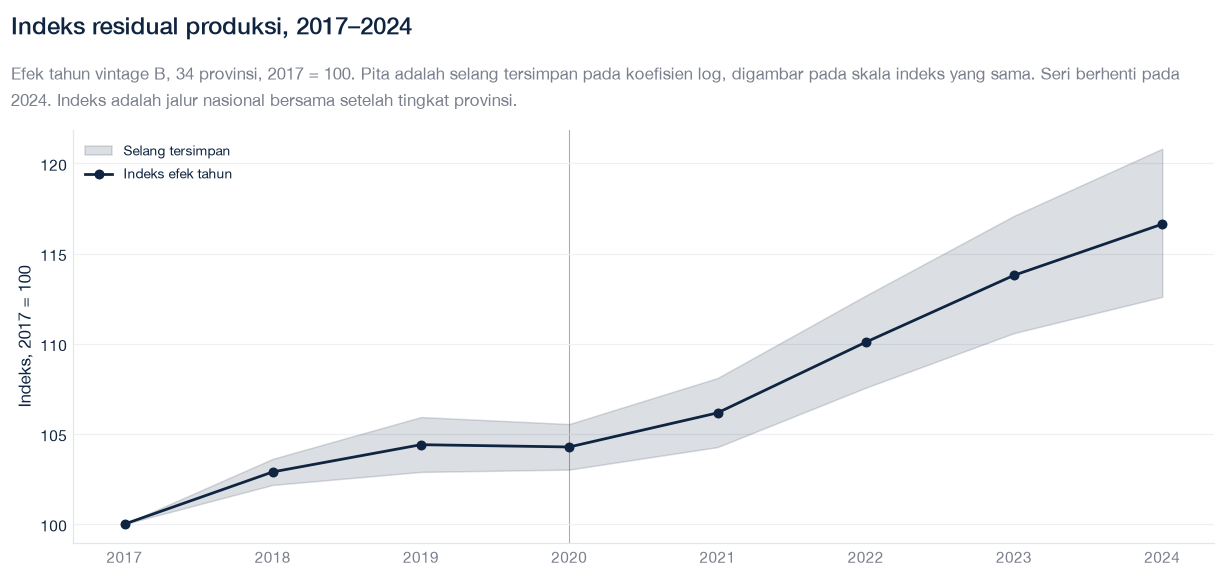

In [2]:
fig, ax = plt.subplots(figsize=(11.2, 5.2))
ax.fill_between(idx.year, idx.lo, idx.hi, color=NAVY, alpha=0.15, label="Selang tersimpan")
ax.plot(idx.year, idx["index"], color=NAVY, marker="o", ms=5.5, lw=1.8, label="Indeks efek tahun")
mark_2020(ax)
ax.set_ylabel("Indeks, 2017 = 100")
ax.set_xticks(list(idx.year))
clean(ax, grid="y")
ax.legend(frameon=False, fontsize=9, loc="upper left")
last = idx.loc[idx.year.eq(2024)].iloc[0]
head(
    fig,
    "Indeks residual produksi, 2017–2024",
    "Efek tahun vintage B, 34 provinsi, 2017 = 100. Pita adalah selang tersimpan pada koefisien log, "
    "digambar pada skala indeks yang sama. Seri berhenti pada 2024. Indeks adalah jalur nasional bersama setelah tingkat provinsi.",
    top=0.82,
)
save(fig, "04_tfp_index.png")


## Akuntansi pertumbuhan, 2018–2024

Batang --> poin persentase per tahun.
Modal, tenaga kerja --> pertumbuhan input × elastisitas.
Sisa --> PDRB riil dikurangi keduanya.
F --> elastisitas tanpa batasan. Lima lain --> elastisitas tersimpan.


04_growth_decomposition.png


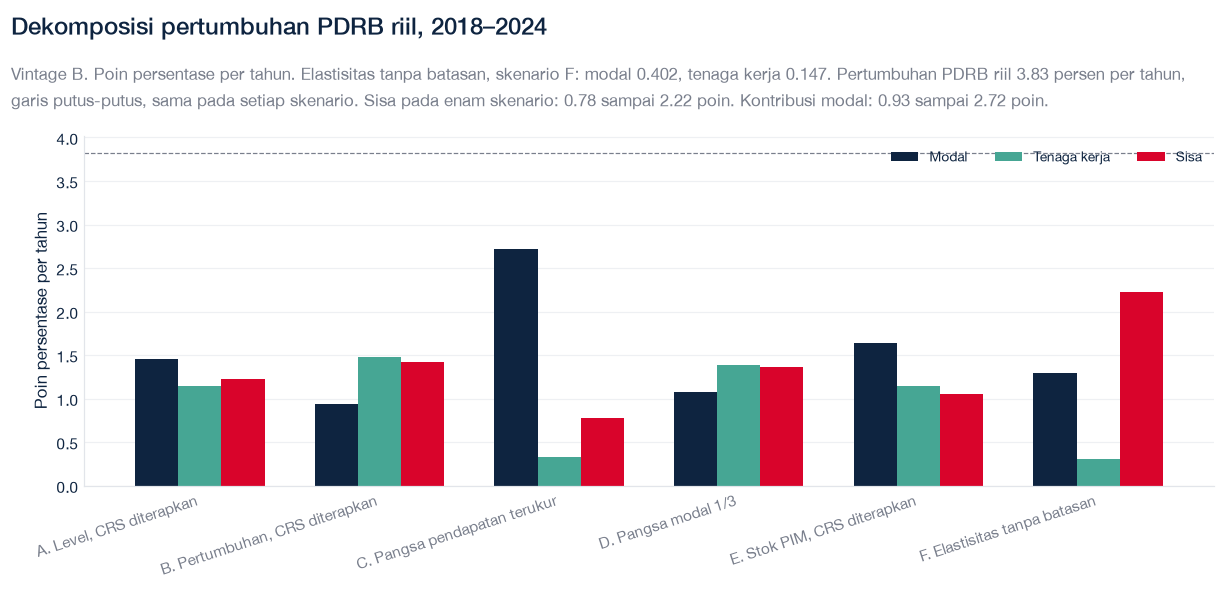

In [3]:
order = decomp.copy()
labels = order["label"].tolist()
x = np.arange(len(order))
width = 0.24
pieces = [
    ("kontrib_K", "Modal", NAVY),
    ("kontrib_L", "Tenaga kerja", TEAL),
    ("sisa", "Sisa", RUST),
]
fig, ax = plt.subplots(figsize=(11.2, 5.6))
for i, (col, name, color) in enumerate(pieces):
    ax.bar(x + (i - 1) * width, order[col], width=width, color=color, label=name)
ax.axhline(order["gY"].iloc[0], color=GRAY, lw=0.8, ls="--")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=18, ha="right")
ax.set_ylabel("Poin persentase per tahun")
clean(ax, grid="y")
ax.legend(frameon=False, ncol=3, fontsize=9, loc="upper right")
frow = order.loc[order.skenario.eq("F. Tanpa CRS")].iloc[0]
head(
    fig,
    "Dekomposisi pertumbuhan PDRB riil, 2018–2024",
    f"Vintage B. Poin persentase per tahun. Elastisitas tanpa batasan, skenario F: modal {frow.b1:.3f}, tenaga kerja {frow.b2:.3f}. "
    f"Pertumbuhan PDRB riil {frow.gY:.2f} persen per tahun, garis putus-putus, sama pada setiap skenario. "
    f"Sisa pada enam skenario: {order.sisa.min():.2f} sampai {order.sisa.max():.2f} poin. "
    f"Kontribusi modal: {order.kontrib_K.min():.2f} sampai {order.kontrib_K.max():.2f} poin.",
    top=0.78,
)
save(fig, "04_growth_decomposition.png")


## Korelat residual

Kiri --> FE2W, efek provinsi dan tahun, SE klaster.
Kanan --> OLS gabungan, tanpa efek itu. Skala berbeda.
Partisipasi sekolah --> tanda dibalik.
Kemiskinan --> sudah −ln(P1+1).
Gini --> tanda seperti di berkas.


04_tfp_correlates.png
Hubungan within yang selang 95%-nya tidak memuat nol:
                 group                      label     b    lo    hi
Ekuitas dan distribusi Indeks pembangunan manusia 0.011 0.002 0.019
Hubungan gabungan yang terbesar:
                     label      b     lo     hi
 Belanja pemerintah daerah  0.438  0.275  0.601
                 Penumpang -0.184 -0.472  0.104
              Kargo kereta  0.175  0.025  0.324
Indeks pembangunan manusia  0.136 -0.060  0.332
            Upah rata-rata  0.113  0.031  0.195
               Kargo udara -0.113 -0.226 -0.001


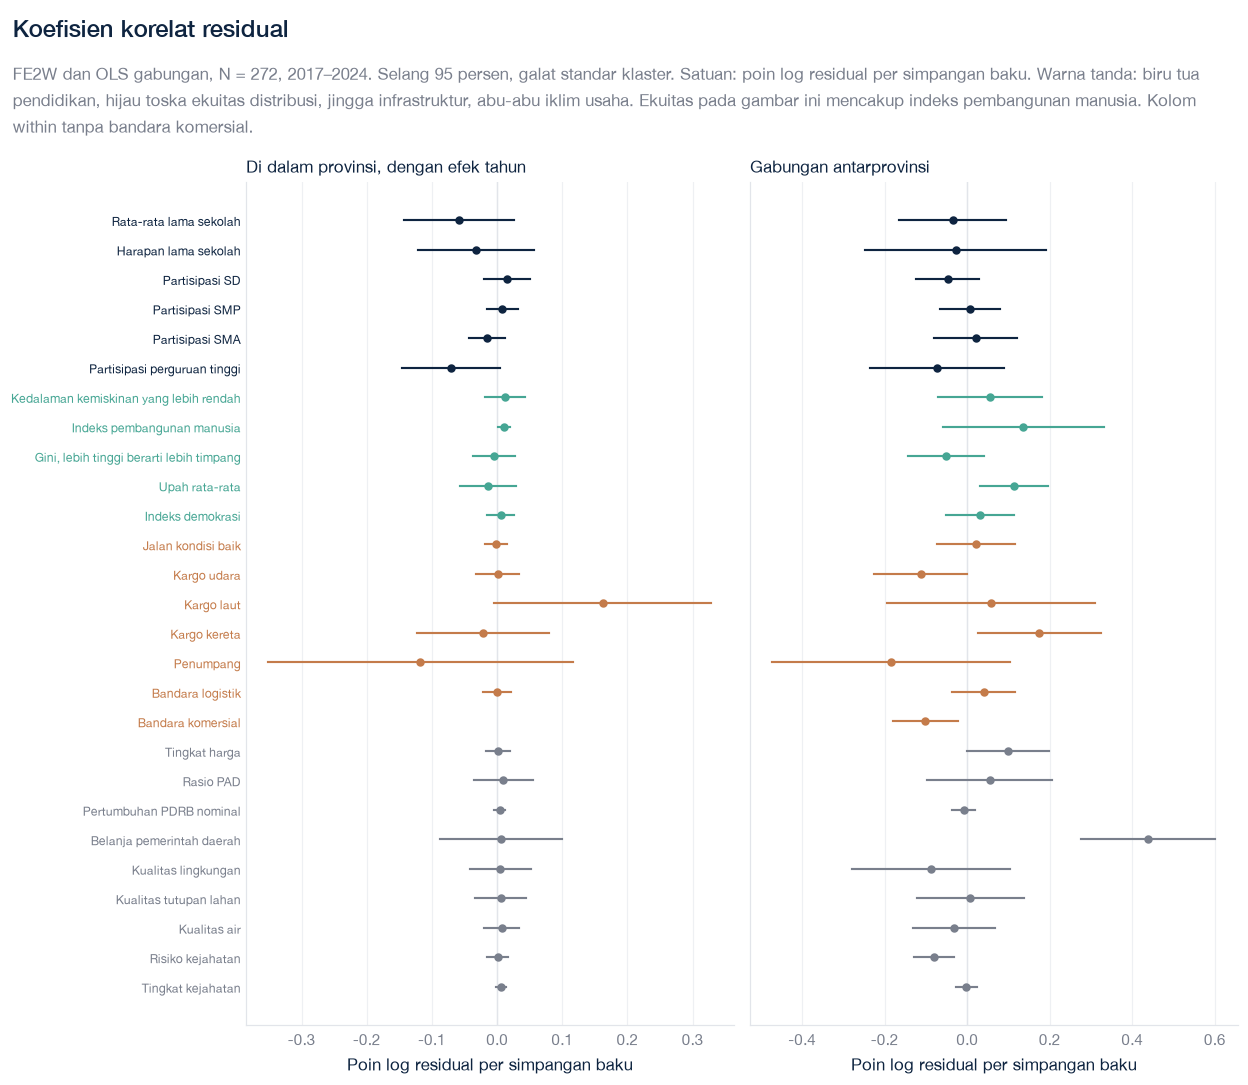

In [4]:
group_color = {
    "Pendidikan": NAVY,
    "Ekuitas dan distribusi": TEAL,
    "Infrastruktur": "#C47B4A",
    "Iklim usaha": GRAY,
}
fe = corr.loc[corr["model"].eq("FE2W")].copy()
po = corr.loc[corr["model"].eq("POLS")].copy()
labels = fe["label"].tolist()
groups = fe["group"].tolist()
y = np.arange(len(labels))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11.4, 9.6), sharey=True)
for ax, frame, title in (
    (axes[0], fe, "Di dalam provinsi, dengan efek tahun"),
    (axes[1], po, "Gabungan antarprovinsi"),
):
    ax.axvline(0, color="#E2E5EA", lw=0.9)
    for yi, rec in zip(y, frame.itertuples(index=False)):
        color = group_color[rec.group]
        if np.isfinite(rec.b):
            ax.plot([rec.lo, rec.hi], [yi, yi], color=color, lw=1.4)
            ax.plot(rec.b, yi, "o", color=color, ms=4.5)
    ax.set_title(title, loc="left", fontsize=11, color=NAVY)
    clean(ax, grid="x")
    ax.set_xlabel("Poin log residual per simpangan baku")
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=8)
label_group = dict(zip(labels, groups))
for tick in axes[0].get_yticklabels():
    tick.set_color(group_color[label_group[tick.get_text()]])
head(
    fig,
    "Koefisien korelat residual",
    f"FE2W dan OLS gabungan, N = 272, 2017–2024. Selang 95 persen, galat standar klaster. "
    "Satuan: poin log residual per simpangan baku. "
    "Warna tanda: biru tua pendidikan, hijau toska ekuitas distribusi, jingga infrastruktur, abu-abu iklim usaha. "
    "Ekuitas pada gambar ini mencakup indeks pembangunan manusia. Kolom within tanpa bandara komersial.",
    top=0.90,
)
save(fig, "04_tfp_correlates.png")
corr.to_csv(vs.OUT / "04_tfp_correlates.csv", index=False)
print("Hubungan within yang selang 95%-nya tidak memuat nol:")
print(fe.loc[fe.excludes_zero, ["group", "label", "b", "lo", "hi"]].round(3).to_string(index=False))
print("Hubungan gabungan yang terbesar:")
print(po.reindex(po.b.abs().sort_values(ascending=False).index)
      .head(6)[["label", "b", "lo", "hi"]].round(3).to_string(index=False))


## Indeks PMA, PMDN, dan residual

2017 = 100. Satu sumbu.
PMA, PMDN --> harga konstan 2010.
Residual --> efek tahun vintage B, berhenti 2024.


04_tfp_investment_timeline.png


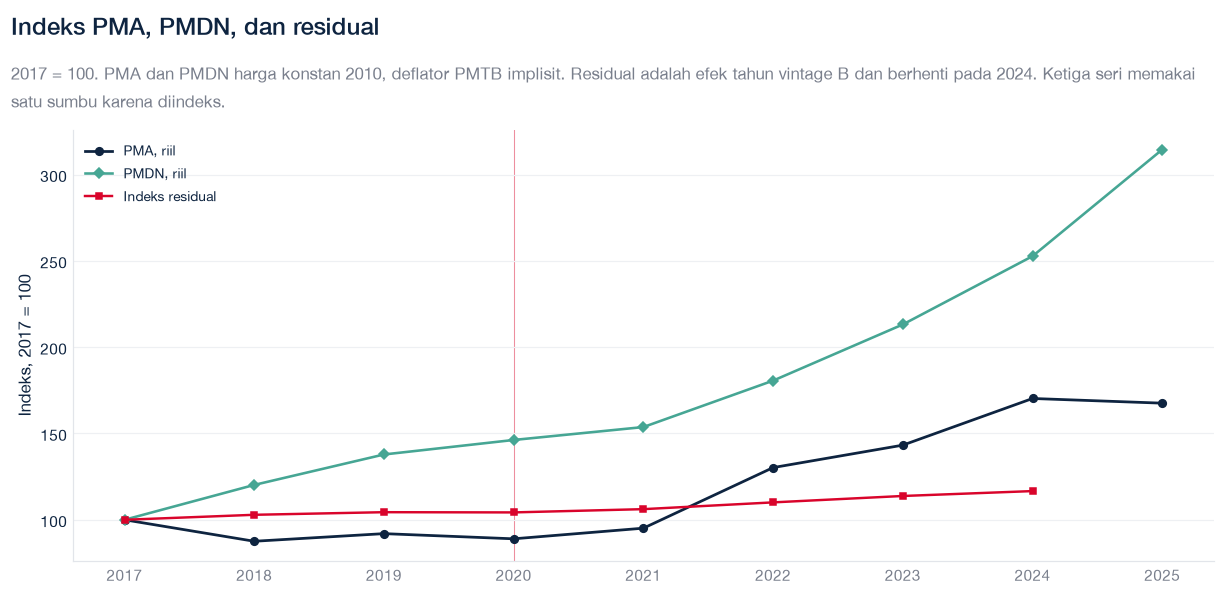

In [5]:
base_pma = nat.loc[nat.year.eq(2017), "pma_real"].iloc[0]
base_pmdn = nat.loc[nat.year.eq(2017), "pmdn_real"].iloc[0]
fig, ax = plt.subplots(figsize=(11.2, 5.4))
ax.plot(nat.year, 100 * nat.pma_real / base_pma, color=NAVY, marker="o", ms=5, lw=1.8, label="PMA, riil")
ax.plot(nat.year, 100 * nat.pmdn_real / base_pmdn, color=TEAL, marker="D", ms=4.5, lw=1.7, label="PMDN, riil")
ax.plot(idx.year, idx["index"], color=RUST, marker="s", ms=4.5, lw=1.6, label="Indeks residual")
mark_2020(ax)
ax.set_ylabel("Indeks, 2017 = 100")
ax.set_xticks(list(nat.year))
clean(ax, grid="y")
ax.legend(frameon=False, fontsize=9, loc="upper left")
head(
    fig,
    "Indeks PMA, PMDN, dan residual",
    "2017 = 100. PMA dan PMDN harga konstan 2010, deflator PMTB implisit. "
    "Residual adalah efek tahun vintage B dan berhenti pada 2024. Ketiga seri memakai satu sumbu karena diindeks.",
    top=0.82,
)
save(fig, "04_tfp_investment_timeline.png")
